# Lab 06: How to choose between a workflow and an agent

**CPU | API key: `OPENAI_API_KEY`**

Lab 05's lookup agent decides every step itself: which tool to call, in what order, and when to stop. Many support
requests do not need that freedom, because you know their steps before they arrive. In this lab you write those
steps as plain Python, a **workflow**, run the same requests through the workflow and through the agent, and count
what each one costs and gets right.

The workflow combines two patterns with standard names. It is a **router**: one model call labels the request, and
your code sends it down the fixed path for that label. Each path is a short **prompt chain**: fetch the facts, then
pass them to one model call that writes the reply.

## Goal

Choose between a workflow and an agent from measurements: build the same support flow both ways, run the same four
requests through both, and compare model calls, tokens and outcomes. The moment that teaches it: on the three
requests it was written for, the workflow makes the same number of model calls in every run (two at most) and uses
about half the agent's tokens or less. Then a rep asks which albums were on Helena's first invoice. No step of the
workflow reads an invoice's albums, so it answers without them (0 of 5 runs pass), where the agent looks the invoice
up and names them (5 of 5 on `gpt-4o-mini`).

## What you will learn

- How to get a label and the arguments a step needs from one structured-output call, and why a valid label can still be wrong.
- How to write a workflow as plain `if`/`else`: fixed Ops API calls per branch and one call to write the reply.
- How to count a run's model calls and tokens with a callback, for a workflow and an agent alike.
- How to run the same requests through both shapes, check every reply in code, and read the table of runs.
- How to decide between a workflow and an agent by asking whether you can list the steps before the request arrives.

## Set up the notebook

Run these two cells first, every time. **Setup** finds the repository folder (on Colab it first copies the repository
and installs the packages). **Config** reads the model names from `models.env` and finds your OpenAI key without
printing it. Lab 00 explains each line.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "JUDGE_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
JUDGE_MODEL       gpt-4o-mini
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


## Start the Ops API

Both shapes read customers and invoices through the Ops API you called by hand in Lab 05. Start it here; it runs in a
background thread until the kernel stops.

In [3]:
from shared.ops_api import start_ops_api

server = start_ops_api()

Ops API started at http://127.0.0.1:8765


The picture shows the two shapes by who decides the next step. In the **workflow** the model makes one choice, a label
with the arguments the steps need; after that your code decides every step, and the dark boxes are the only model
calls. In the **agent** the model chooses every next step: which tool, how often, and when to reply.

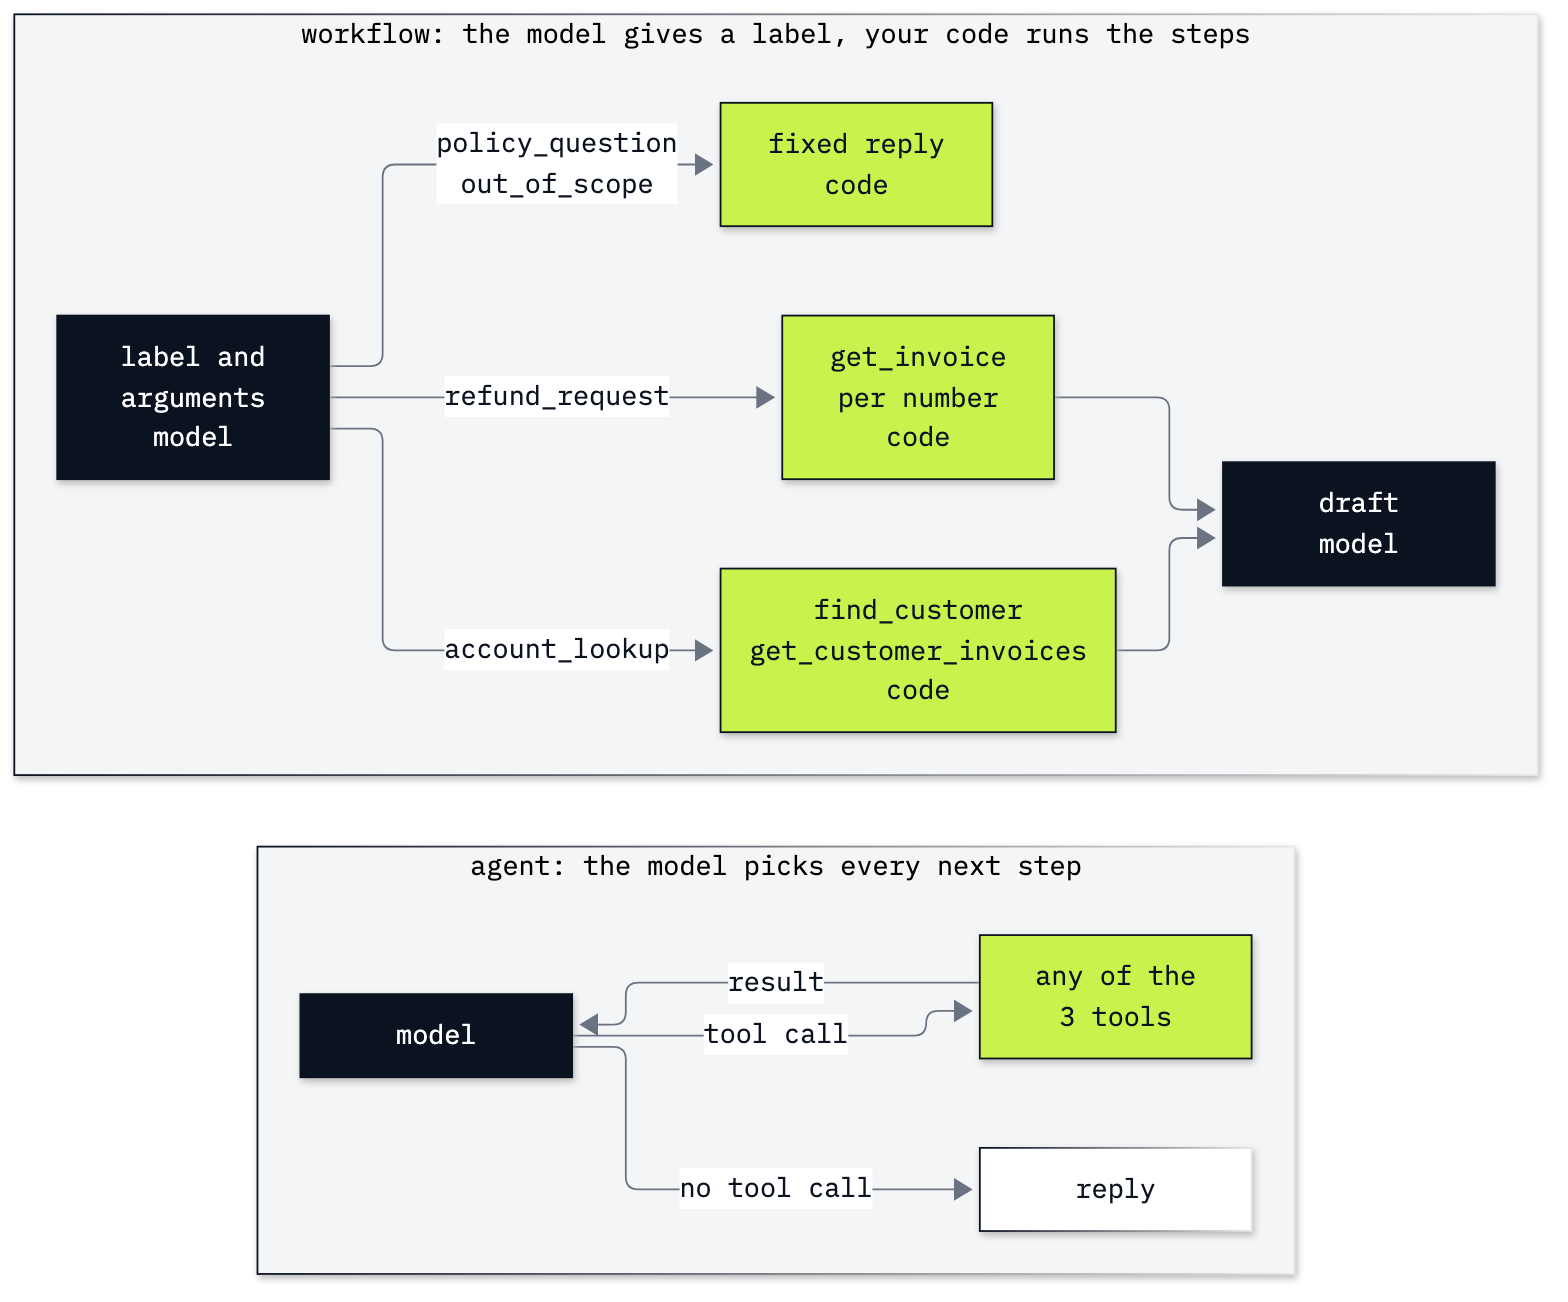

In [4]:
from IPython.display import Image
Image(filename=ROOT / "06_Chain_And_Router" / "resources" / "workflow_and_agent.png", width=700)

---

## Part A: Label a request and pull out its arguments

A workflow must know what kind of request it has before it can pick its steps. This part gets that from one model
call that returns data instead of prose.

**Structured output** makes the model return data that matches a schema you give it. Here the schema is a Pydantic
class, `Request`, with three fields:

- `label`: `Literal[...]` lists the four allowed labels, so the model must pick one of them. Your code branches on it.
- `customer_name`: the name the account steps need. `str | None` lets the model answer "no name in this message".
- `invoice_ids`: the invoice numbers the refund steps need, as a list of whole numbers.

Each `Field(description=...)` tells the model what belongs in that field. `with_structured_output(Request)` turns the
class into a JSON schema, like the one you wrote for a tool in Lab 01, sends it with the request, and parses the reply
into a `Request` object.

In [5]:
from typing import Literal
from pydantic import BaseModel, Field
from shared.settings import chat_model

class Request(BaseModel):
    label: Literal["policy_question", "account_lookup", "refund_request", "out_of_scope"]
    customer_name: str | None = Field(description="The customer's name, if the message names one.")
    invoice_ids: list[int] = Field(description="Invoice numbers in the message, digits only.")

model = chat_model(settings)
labeller = model.with_structured_output(Request)
print(labeller.invoke("How many invoices does Puja Srivastava have, and what is her total?"))

label='account_lookup' customer_name='Puja Srivastava' invoice_ids=[]


One call gave a label your code can branch on and the name the account steps need. The result is a `Request` object,
not text: your code reads `request.label` and `request.customer_name` like any attribute, and `label` can only hold
one of the four values. The model does not look anything up here; it only reads the message.

These are the four requests the rest of the lab uses. The first three are the kinds this workflow is written for: an
account lookup, a refund check, and a message outside the copilot's job. The fourth starts like an account lookup and
then asks for something the account steps do not fetch: the albums on one invoice. Predict a label for each, then run
each one three times, because a label is model output and one run is not a count.

In [6]:
REQUESTS = [
    "How many invoices does Puja Srivastava have, and what is her total?",
    "Ticket 14: the customer says she was charged twice, invoices 9001 and 9002. Check them before we refund.",
    "Write me a poem about jazz.",
    "How many invoices does Helena Holý have, and which albums were on her first one?",
]

for number, text in enumerate(REQUESTS, 1):
    for run in range(3):
        request = labeller.invoke(text)
        print(f"{number}. {request.label:15} name={request.customer_name}, invoices={request.invoice_ids}")

1. account_lookup  name=Puja Srivastava, invoices=[]


1. account_lookup  name=Puja Srivastava, invoices=[]


1. account_lookup  name=Puja Srivastava, invoices=[]


2. refund_request  name=None, invoices=[9001, 9002]


2. refund_request  name=None, invoices=[9001, 9002]


...

3. out_of_scope    name=None, invoices=[]


3. out_of_scope    name=None, invoices=[]


4. account_lookup  name=Helena Holý, invoices=[]


4. account_lookup  name=Helena Holý, invoices=[]


4. account_lookup  name=Helena Holý, invoices=[]


Every request got the same label and arguments in 3 of 3 runs. A label is still model output, so it can change from
run to run or on another model: the schema guarantees the shape of the answer, never that what is in it is right. Request 4 is labelled `account_lookup`, the right label: nothing in it tells your code that this request needs more than the account steps.

### Checkpoint A

| You should see | Our run |
|---|---|
| One call | `label='account_lookup' customer_name='Puja Srivastava' invoice_ids=[]` |
| Four requests, three runs each | the same label and arguments in 3 of 3: `account_lookup` for Puja, `refund_request` with `[9001, 9002]`, `out_of_scope` for the poem, `account_lookup` for Helena Holý  with `invoice_ids=[]` |

---

## Part B: Write the workflow as plain Python

Now your code decides every step after the label. Each branch makes fixed Ops API calls, and where the rep needs a
sentence, one model call writes it from the facts the branch fetched.

### Call the tools from your own code

The steps use Lab 05's three read tools, imported one by one from `shared/ops_tools.py`. A tool is still an ordinary
function under its decorator: `.invoke` with the arguments runs it, exactly as the agent's loop does when the model
asks for it. Here no model chooses the call.

In [7]:
import json
from shared.ops_tools import find_customer, get_customer_invoices, get_invoice

print(find_customer.invoke({"name": "Puja Srivastava"}))

[{"customer_id": 59, "name": "Puja Srivastava", "country": "India", "support_rep": "Jane Peacock"}]


The tool returns the API's JSON as text, the same text the model would read. Your code can parse it with
`json.loads` and pass `customer_id` on to the next call.

These are Lab 05's three read tools, kept in `shared/` so that later labs can import them. All three call the API
through one function, `_get`: Lab 05's `api_get`, with one change. Read it before you use the tools.

In [8]:
import inspect
import shared.ops_tools as ops_tools

print(inspect.getsource(ops_tools._get))

def _get(path: str, **params) -> str:
    try:
        r = httpx.get(API + path, params=params, timeout=TIMEOUT)
    except (httpx.TimeoutException, httpx.ConnectError):
        return "The Ops API did not answer. Try again in a moment."
    if r.status_code == 404:
        return "Not found: " + r.json()["detail"]
    r.raise_for_status()
    return json.dumps(r.json(), ensure_ascii=False)



A 404 comes back as *Not found* text, as in Lab 05 Part E. The change is in the first lines: a service that does not
answer also comes back as a sentence, *The Ops API did not answer*, instead of an exception, so a run never stops on
it. Code that reads a tool's text must check it first: `account_facts` below passes such a sentence on instead of
reading it as JSON. One more difference: this `get_customer_invoices` has no rep check, unlike the last version in
Lab 05 Part D. This lab passes no rep, so the comparison is between the two shapes only; Lab 12 brings the same check
back for its ticket search.

### Write the steps for two branches

The account branch makes two API calls, always in this order: find the customer, then list her invoices. The refund
branch fetches every invoice the rep named. Neither calls a model.

In [9]:
def account_facts(request):
    found = find_customer.invoke({"name": request.customer_name})
    if not found.startswith("["):              # not a list of customers: the API's sentence, passed on as a fact
        return found
    customers = json.loads(found)
    if not customers:
        return f"No customer named {request.customer_name}."
    invoices = get_customer_invoices.invoke({"customer_id": customers[0]["customer_id"]})
    return json.dumps(customers[0]) + "\n" + invoices

def refund_facts(request):
    return "\n".join(get_invoice.invoke({"invoice_id": number}) for number in request.invoice_ids)

request = labeller.invoke(REQUESTS[0])
facts = account_facts(request)
print(facts[:400])

{"customer_id": 59, "name": "Puja Srivastava", "country": "India", "support_rep": "Jane Peacock"}
{"customer_id": 59, "support_rep": "Jane Peacock", "count": 6, "total": 36.64, "invoices": [{"invoice_id": 23, "date": "2009-04-05", "total": 3.96}, {"invoice_id": 45, "date": "2009-07-08", "total": 5.94}, {"invoice_id": 97, "date": "2010-02-26", "total": 1.99}, {"invoice_id": 218, "date": "2011-08-20


Puja is customer 59, and her invoice list starts with the count and the total. The second call used the
`customer_id` your code took from the first answer.

### Write the reply from the facts

The rep wants a sentence, not JSON. The draft step is one model call that gets the rep's message and only the facts
the branch fetched. "Only these facts" matters: when a fact is missing, the model should say so rather than fill the
gap from what it has read elsewhere.

Fetch, then draft, is **prompt chaining**: each step's output is the next step's input, in an order your code fixes.

In [10]:
DRAFT = ("Answer the support rep's message in two or three sentences, using only these facts from the Ops API.\n"
         "Message: {text}\nFacts: {facts}")

def draft(text, facts, config=None):
    return model.invoke(DRAFT.format(text=text, facts=facts), config).text

print(draft(REQUESTS[0], facts))

Puja Srivastava has a total of 6 invoices. The total amount for these invoices is 36.64.


### Join the steps with `if` and `else`

Now the whole workflow, a **router**: one classification, then a fixed path per label. The label picks the branch,
and every branch is fixed. Two labels need no model after the
label: an out-of-scope message gets a fixed reply, and so does a policy question, because this copilot cannot read
the handbook yet (Lab 08 adds a search). `config` is for the counter you add in Part D; leave it out for now.

In [11]:
POLICY_REPLY = "I can't read the handbook yet. Please check the policy in the support handbook."
DECLINE = "I can help with Chinook customers and invoices. That is outside what I do."

def workflow(text, config=None):
    request = labeller.invoke(text, config)                   # model call 1: label and arguments
    if request.label == "account_lookup":
        return draft(text, account_facts(request), config)    # model call 2: the reply
    elif request.label == "refund_request":
        return draft(text, refund_facts(request), config)     # model call 2: the reply
    elif request.label == "policy_question":
        return POLICY_REPLY                                   # no second call
    else:
        return DECLINE                                        # out_of_scope: no second call

Predict before you run: how many model calls does the refund check make, and how many does the poem make?

In [12]:
for text in REQUESTS[1:3]:
    print(workflow(text))
    print()

Upon reviewing invoices 9001 and 9002, both were charged to the same customer on the same date for the same album, each totaling $9.99. It appears the customer was charged twice, so we can proceed with the refund.



I can help with Chinook customers and invoices. That is outside what I do.



Ticket 14 made two model calls, the label and the reply, and the reply compares the two invoices: both 9.99, for the same album, on the same date. The poem made one call, the label, and the fixed reply came from your code. Part D counts the calls instead of reading them off the code.

### Checkpoint B

| You should see | Our run |
|---|---|
| `find_customer` for Puja | customer 59, India, Jane Peacock |
| Her facts and reply | her row and her invoice list (count 6, total 36.64); a reply with *6 invoices* and *36.64* |
| Ticket 14 and the poem | a note on the two 9.99 charges for the same album on the same date; the fixed out-of-scope reply |

---

## Part C: Rebuild the Lab 05 agent

The agent gets the same three tools and chooses the calls itself. This is Lab 05's lookup agent, with its prompt.

In [13]:
from langchain.agents import create_agent

PROMPT = ("You are Chinook's support copilot. You help support reps with questions about customers and invoices. "
          "Use the tools to look up facts, and quote numbers exactly as the tools return them.")
agent = create_agent(model, tools=[find_customer, get_customer_invoices, get_invoice], system_prompt=PROMPT)

Predict before you run: which tools will the agent call for Puja's question, and how many model calls will it make?

In [14]:
result = agent.invoke({"messages": [{"role": "user", "content": REQUESTS[0]}]})

for message in result["messages"]:
    shown = message.tool_calls if message.type == "ai" and message.tool_calls else message.text[:110]
    print(f"{message.type:6}", shown)

human  How many invoices does Puja Srivastava have, and what is her total?
ai     [{'name': 'find_customer', 'args': {'name': 'Puja Srivastava'}, 'id': 'call_okD1vomNMPfRlMUYrb22JrQh', 'type': 'tool_call'}]
tool   [{"customer_id": 59, "name": "Puja Srivastava", "country": "India", "support_rep": "Jane Peacock"}]
ai     [{'name': 'get_customer_invoices', 'args': {'customer_id': 59}, 'id': 'call_1uzkxtxkxs3r20t1nZOMnXI9', 'type': 'tool_call'}]
tool   {"customer_id": 59, "support_rep": "Jane Peacock", "count": 6, "total": 36.64, "invoices": [{"invoice_id": 23,
ai     Puja Srivastava has a total of **6 invoices** and the total amount is **$36.64**.


The agent made the same two API calls as the workflow's account branch, in the same order, and passed `customer_id` 59 on by itself. Choosing them cost a model call each: three calls in all, where the workflow needed two.

Part D runs every request through the agent, so give it the same shape as `workflow`: text and config in, the reply
out.

In [15]:
def ask_agent(text, config=None):
    result = agent.invoke({"messages": [{"role": "user", "content": text}]}, config)
    return result["messages"][-1].text

### Checkpoint C

| You should see | Our run |
|---|---|
| Tools called | `find_customer`, then `get_customer_invoices` with `customer_id` 59 |
| The reply | 6 invoices, 36.64 |

---

## Part D: Run the same requests through both

To choose between the shapes you need the same three numbers from every run: model calls, tokens, and whether the
reply was right. This part counts the first two with a callback, checks the third in code, and runs each request five
times through each shape.

### Count model calls and tokens

A **callback** is an object LangChain calls at events in a run. `UsageMetadataCallbackHandler` is LangChain's own token
counter: after every chat model call (`on_llm_end`) it adds the call's `usage_metadata` (Lab 01) to a total per model.
`Meter` adds a count of the calls. Pass it in the run's config under `callbacks`, and every model call made with that
config reports to it: the label, the draft, and each step of the agent's loop.

In [16]:
from langchain_core.callbacks import UsageMetadataCallbackHandler

class Meter(UsageMetadataCallbackHandler):
    # LangChain's token counter, plus a count of model calls.
    def __init__(self):
        super().__init__()
        self.calls = 0

    def on_llm_end(self, response, **kwargs):
        super().on_llm_end(response, **kwargs)
        self.calls += 1

    def tokens(self):
        return sum(usage["total_tokens"] for usage in self.usage_metadata.values())

meter = Meter()
reply = workflow(REQUESTS[0], {"callbacks": [meter]})
print("calls:", meter.calls, "| tokens:", meter.tokens())
print(meter.usage_metadata)

calls: 2 | tokens: 465
{'gpt-4o-mini-2024-07-18': {'total_tokens': 465, 'input_token_details': {'cache_read': 0, 'cache_creation': 0}, 'input_tokens': 409, 'output_tokens': 56, 'output_token_details': {'reasoning': 0}}}


Two calls, the label and the draft. `usage_metadata` is keyed by the dated model that answered, and `total_tokens` is
input plus output (on a reasoning model, output includes its reasoning tokens).

### Write the checks before the runs

Each request has facts a right reply must contain, written down before any run. The four checks are the answer key:
the model never sees them. They describe the reply we want, so either shape may fail one it was not built for.

| # | Passes when | Why |
|---|---|---|
| 1 | the reply gives Puja's 6 invoices and her total, 36.64 | the two facts the rep asked for |
| 2 | the reply names invoices 9001 and 9002 and the amount, 9.99 | the rep must see both charges before a refund |
| 3 | the reply is not a poem: fewer than four lines | the copilot's job is customers and invoices; a rough check, since a poem runs to more lines |
| 4 | the reply gives Helena's 7 invoices **and** names every album on her first invoice, number 46 | the second half of the question asks which albums |

Invoice 46 holds tracks from five albums, read from the Ops API in the next cell, so the check compares against the
real list. A reply that names two of them "among others" fails: the rep asked which albums.

In [17]:
import re

ALBUMS_46 = sorted({line["album"] for line in json.loads(get_invoice.invoke({"invoice_id": 46}))["lines"]})
print(ALBUMS_46)

def check(number, reply):
    text = reply.lower()
    if number == 1:
        return re.search(r"\b(6|six)\b", text) is not None and "36.64" in text
    if number == 2:
        return "9001" in text and "9002" in text and "9.99" in text
    if number == 3:
        return reply.count("\n") < 3
    return re.search(r"\b(7|seven)\b", text) is not None and all(album.lower() in text for album in ALBUMS_46)

['Are You Experienced?', 'Emergency On Planet Earth', 'Get Born', 'Synkronized', 'The Return Of The Space Cowboy']


`ALBUMS_46` keeps each album name once (a set), sorted. `check` lowercases the reply first. In the patterns, `\b`
marks the edge of a word, so the *6* inside *36.64* does not count as six invoices.

Before forty runs, try the checks on one. `reply` still holds the workflow's answer to request 1 from the `Meter`
cell. Check it, then a reply written by hand that gives the count and leaves out the total.

In [18]:
print(reply)
print("check 1 on this run:            ", check(1, reply))
print("check 1 on a reply without the total:", check(1, "Puja Srivastava has 6 invoices."))

Puja Srivastava has a total of 6 invoices, amounting to $36.64. If you need any further details, feel free to ask!
check 1 on this run:             True
check 1 on a reply without the total: False


The real reply passes check 1: it has *6 invoices* and *$36.64*. The hand-written reply has the count and no total, so
it fails. Each check asks only its own request's question, so the loop below passes every reply to `check` with its
request's number.

### Run both shapes five times

Forty runs: four requests, two shapes, five rounds. Each run gets a new `Meter`, and its reply is checked and kept.
This is the cell that costs the most in the lab (a few US cents with `gpt-4o-mini`).

In [19]:
rows = []
for number, text in enumerate(REQUESTS, 1):
    for shape, run in (("workflow", workflow), ("agent", ask_agent)):
        for _ in range(5):
            meter = Meter()
            reply = run(text, {"callbacks": [meter]})
            rows.append({"request": number, "shape": shape, "passed": check(number, reply),
                         "calls": meter.calls, "tokens": meter.tokens(), "reply": reply})
print(len(rows), "runs")

40 runs


One line per request and shape: how many runs passed, the model calls (one number when every run made the same), and
the tokens, lowest to highest. This cell only formats the table from `rows`: run it, and read its output rather than
its f-strings.

In [20]:
print(f"{'request':9}{'shape':10}{'passed':9}{'calls':>6}{'tokens':>15}")
for number in range(1, 5):
    for shape in ("workflow", "agent"):
        mine = [row for row in rows if row["request"] == number and row["shape"] == shape]
        calls = sorted({row["calls"] for row in mine})
        tokens = sorted(row["tokens"] for row in mine)
        calls_text = str(calls[0]) if len(calls) == 1 else f"{calls[0]}-{calls[-1]}"
        print(f"{number:<9}{shape:10}{sum(row['passed'] for row in mine)} of {len(mine)}"
              f"{calls_text:>8}{tokens[0]:>8,}-{tokens[-1]:,}")

request  shape     passed    calls         tokens
1        workflow  5 of 5       2     464-468
1        agent     5 of 5       3     984-984
2        workflow  5 of 5       2     441-461
2        agent     5 of 5       2     802-841
3        workflow  5 of 5       1     143-143
3        agent     0 of 5       1     340-374
4        workflow  0 of 5       2     491-502
4        agent     5 of 5       4   2,019-2,043


On the three requests it was written for, the workflow passed every run and used fewer tokens every time. Requests 1 and 2 passed 5 of 5 in both shapes, at 441 to 468 tokens for the workflow and 802 to 984 for the agent, whose every call carries the prompt, the tool schemas and the conversation so far. On the poem the workflow gave its fixed reply at 1 call, and the agent wrote a poem in 5 of 5: its prompt has no rule against poems, and the workflow's rule is code, so the poem compares a rule with no rule, not the two shapes. Request 4 is the moment: the workflow passed 0 of 5 at its usual 2 calls, the agent 5 of 5 at 4 calls and about 2,030 tokens, naming all five albums each time.

### Read the failures

A count says how often a shape failed, not how. Print every reply that failed its check.

In [21]:
for row in rows:
    if not row["passed"]:
        print(f"request {row['request']} {row['shape']:8}", row["reply"][:160].replace("\n", " / "))

request 3 agent    In the smoky haze of a dim café,   / Notes dance lightly, come what may,   / Trumpets beckon, a sultry call,   / As the bassline whispers, "Lose it all."   /  / Saxophone
request 3 agent    **Jazz Reverie** /  / In smoky rooms where shadows play,   / Notes dance and swirl, then drift away,   / A trumpet wails, a saxophone sighs,   / Beneath the dim lights, t
request 3 agent    **Whispers of Jazz** /  / In the heart of the night, where shadows dance free,   / A trumpet calls softly, a sweet melody.   / The saxophone wails with a sultry embrace
request 3 agent    **In the Heart of Jazz** /  / In smoky rooms where shadows dance,   / The saxophone whispers, takes a chance.   / A trumpet blares a golden cry,   / As rhythms pulse and 
request 3 agent    **In the Heart of Jazz** /  / In the smoky haze of a nighttime bar,   / A trumpet wails, reaching for the stars.   / Fingers dance on keys, a saxophone sighs,   / Rhythms
request 4 workflow Helena Holý has a total of 7 invo

The agent's five poems, and the workflow's five replies to request 4: three say the albums *are not provided*, and two give the count, the date and the total of her first invoice without naming an album. None invented an album, because the draft step uses only the facts it got. The workflow did what it was written to do; it was not written for this request.

### Checkpoint D

| You should see | Our run |
|---|---|
| Requests 1 and 2 | 5 of 5 in both shapes; workflow 2 calls, about 465 and 450 tokens; agent 3 and 2 calls, about 985 and 820 |
| Request 3, the poem | workflow 5 of 5 at 1 call; agent 0 of 5, a poem each time |
| Request 4, the albums | workflow 0 of 5 at 2 calls; agent 5 of 5 at 4 calls, about 2,030 tokens |
| Model calls in all | 85 for the forty runs: workflow 35, agent 50 |

Replies and token counts vary between runs, and again on another model: compare the counts and the kinds of failure,
not our wording.

---

## Part E: Choose a workflow or an agent

The question that decides it: **can you list the steps before the request arrives?** If you can, write them as a
workflow; your code runs them the same way every time, and you pay only for the model calls you wrote. Passing a
result on (a customer id to the next call) does not need an agent; your code did that in every account run, and code
can also pick a branch or repeat a step from a result. The difference is who chooses: a workflow defines the steps
and the rules for choosing among them in code; an agent lets the model choose the next action from the results it
sees. Use an agent when you cannot write those rules in advance, and pay for its choices.

### What the runs showed

| Shape | Who decides the next step | Requests it was written for | The request it was not written for |
|---|---|---|---|
| workflow | the model gives a label, then your code | requests 1 and 2: 10 of 10, 2 calls every run, 441 to 468 tokens; the poem: 5 of 5 at 1 call | 0 of 5 at 2 calls: it answered the part its steps fetched |
| agent | the model, at every step | requests 1 and 2: 10 of 10, 2 or 3 calls, 802 to 984 tokens; the poem: 0 of 5 | 5 of 5 at 4 calls and about 2,030 tokens |

The poem row does not compare the two shapes. The workflow's scope rule is code and runs every time; the agent's
prompt has no scope rule at all. To compare them on scope, add a rule to the agent's prompt and count it over runs,
as Lab 02 did for its prompt rules.

The workflow's failure raised no error: the label was right, every API call worked, and the reply was correct as far
as it went. Only the check in code showed it, so a workflow needs checks as much as an agent does.

A router can fail in two different ways, and they have different fixes. A **misroute** is a wrong label, for example the poem labelled `policy_question`: clearer label definitions or examples fix it. A request **no route covers**,
like request 4, has the right label and still fails: only a new branch, or the agent, fixes it.

### Four support jobs

For each job, write workflow or agent, and the fact that decides it.

| # | Job |
|---|---|
| 1 | Every night, export the new tickets and count them by country. |
| 2 | For each refund ticket, fetch the invoices it names and write a note for the rep. |
| 3 | Find out why a refund was never paid; where to look next depends on what each check finds. |
| 4 | Answer any rep question about customers and invoices. |

Compare yours with this answer:

| # | Shape | Deciding fact |
|---|---|---|
| 1 | workflow | fixed steps and no choice to make; it needs no model at all |
| 2 | workflow | the same calls for every ticket of that kind, like this lab's refund branch |
| 3 | agent | each check depends on what the last one found |
| 4 | agent | the steps are not known until the question arrives, as request 4 showed |

### The copilot's shape

Reps ask open questions, so the copilot stays an agent. Where one kind of request is common and its steps never
change, a workflow does that job for less, the same way every time. The two combine: a router in front, a workflow for
the kinds you listed, and the agent for the rest (the second challenge). Anthropic's guide to building agents gives
the same advice: start with the simplest shape that works, and add an agent's freedom only where it pays for itself.

## What you can do now

- Get a label and the arguments a step needs from one `with_structured_output` call.
- Write a workflow as plain `if`/`else`, with fixed Ops API calls per branch and one call to write the reply.
- Count a run's model calls and tokens with a callback passed in the run's config.
- Run the same requests through a workflow and an agent, check every reply in code, and read the failures.
- Choose a workflow when you can list the steps in advance and an agent when you cannot, and back the choice with
  numbers.

The core lab ends here. Going further is optional, and the Challenge after it needs only the core.

## Going further

### The same workflow as a LangGraph graph

LangGraph is the runtime under `create_agent`, and its own API, `StateGraph`, writes a workflow as a graph. Three
words you need:

- **state**: a dictionary every step can read; its keys are declared in a `TypedDict`;
- **node**: a function that takes the state and returns only the keys it adds;
- **edge**: "after this node, run that one". A **conditional edge** calls your function to pick the next node.

Each node below wraps a function you already wrote.

In [22]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class FlowState(TypedDict, total=False):
    text: str
    request: Request
    facts: str
    reply: str

def classify(state):  return {"request": labeller.invoke(state["text"])}
def account(state):   return {"facts": account_facts(state["request"])}
def refund(state):    return {"facts": refund_facts(state["request"])}
def write(state):     return {"reply": draft(state["text"], state["facts"])}
def policy(state):    return {"reply": POLICY_REPLY}
def decline(state):   return {"reply": DECLINE}

def pick_branch(state):          # the if/else: the label names the next node
    return state["request"].label

The edges replace the `if` and `else`. `add_conditional_edges` lists every node `pick_branch` may return, and
`compile()` checks the wiring.

In [23]:
builder = StateGraph(FlowState)
for name, node in [("classify", classify), ("account_lookup", account), ("refund_request", refund),
                   ("draft", write), ("policy_question", policy), ("out_of_scope", decline)]:
    builder.add_node(name, node)
builder.add_edge(START, "classify")
builder.add_conditional_edges("classify", pick_branch,
                              ["account_lookup", "refund_request", "policy_question", "out_of_scope"])
builder.add_edge("account_lookup", "draft")
builder.add_edge("refund_request", "draft")
for name in ("draft", "policy_question", "out_of_scope"):
    builder.add_edge(name, END)
graph = builder.compile()

meter = Meter()
for update in graph.stream({"text": REQUESTS[3]}, {"callbacks": [meter]}, stream_mode="updates"):
    for node, added in update.items():
        print(f"{node:15} adds {list(added)}")
print("calls:", meter.calls)

classify        adds ['request']
account_lookup  adds ['facts']


draft           adds ['reply']
calls: 2


Request 4 ran `classify`, `account_lookup` and `draft`, each adding its own key, in 2 calls: the same path and cost as `workflow`. The graph changes how the steps are written, not which steps exist, so request 4 fails the same way.
What a graph adds is the structure around the steps: a saved state after every node (with a checkpointer, a run can
pause for a person and resume, as in Lab 09), each step's progress as it happens, and the same tools you use for
agents. Reach for it when a fixed path needs those; plain Python is enough for this one.

### Stop the Ops API

The server thread stops when the kernel stops; this cell stops it now.

In [24]:
if server is not None:          # None: another notebook runs the Ops API; stop it there
    server.should_exit = True

## Challenge

Use only what this lab showed. A worked solution is in `solved/` for the instructor. For each task, keep the printed checks and your answer to Explain. The next cell starts the Ops API
again: the cell above stopped it.

1. **Add a step for the albums.** **Start from** the second cell below: `RequestWithInvoice` adds a field
   `wants_first_invoice`, and `workflow_2` uses it. Complete `account_facts_2`: when the field is true, take the
   first invoice's number from the invoice list, call `get_invoice` with it, add the number to `fetched` and the
   invoice to the facts. The cell runs request 4 three times.

   **Check:** three things, printed apart: the label set the field to `True`; the new step fetched invoice 46, an API
   call, so the model calls stay at 2; and the reply names all five albums of invoice 46. If it names only some, read `DRAFT`'s instruction. Then ask *Which albums were
   on Helena Holý's last invoice?* with `workflow_2`, and print `fetched` and the reply.

   **Explain:** what is the workflow missing for the last-invoice question, and what would you have to change? The
   agent needed no change.

2. **A label in front of the agent.** **Start from** `gated` in the third cell below and complete its two TODOs. The
   cell runs the four requests once each through the agent alone and through `gated`, each with a `Meter`. Predict
   first: which requests reach the agent?

   **Check:** the poem gets the fixed reply at 1 call; every other request reaches the agent and costs one model call
   more than the agent alone.

   **Explain:** when does a label in front pay for its extra call?

In [ ]:
server = start_ops_api()      # the cell above stopped the Ops API

**Task 1.** The field, `account_facts_2` to complete, and request 4 three times:

In [ ]:
class RequestWithInvoice(Request):
    wants_first_invoice: bool = Field(description="True when the rep asks about the customer's first invoice.")


labeller_2 = model.with_structured_output(RequestWithInvoice)
fetched = []          # the invoices your new step fetched, so the check can see the extra API call


def account_facts_2(request):
    if not request.customer_name:         # the label found no name: tell the draft instead of calling the API
        return "The message names no customer."
    facts = account_facts(request)        # the customer, then her invoice list as JSON on the second line
    # TODO: when request.wants_first_invoice is True, take the first invoice_id from that list, call get_invoice
    #       with it, append the number to fetched, and add the invoice's text to facts
    return facts


The workflow with the new label, and request 4 three times:

In [ ]:
def workflow_2(text, config=None):
    request = labeller_2.invoke(text, config)                 # model call 1: the label, now with the new field
    print("   wants_first_invoice:", request.wants_first_invoice)
    if request.label == "account_lookup":
        return draft(text, account_facts_2(request), config)  # model call 2: the reply
    elif request.label == "refund_request":
        return draft(text, refund_facts(request), config)
    elif request.label == "policy_question":
        return POLICY_REPLY
    else:
        return DECLINE


for run in range(3):
    fetched.clear()
    meter = Meter()
    reply = workflow_2(REQUESTS[3], {"callbacks": [meter]})
    named = [album for album in ALBUMS_46 if album.lower() in reply.lower()]
    print(f"run {run + 1}: fetched {fetched} | model calls {meter.calls} | "
          f"albums of invoice 46 named: {len(named)} of {len(ALBUMS_46)}")

**Task 2.** `gated` to complete, and the four requests through both:

In [ ]:
def gated(text, config=None):
    request = labeller.invoke(text, config)
    # TODO: return DECLINE for an out_of_scope request
    # TODO: otherwise return ask_agent(text, config), passing config on so the Meter counts the agent's calls
    raise NotImplementedError("Complete gated.")


try:
    for number, text in enumerate(REQUESTS, 1):
        for shape, run in (("agent", ask_agent), ("gated", gated)):
            meter = Meter()
            reply = run(text, {"callbacks": [meter]})
            print(f"{number}. {shape:6} passed={check(number, reply)!s:5} calls={meter.calls} tokens={meter.tokens()}")
except NotImplementedError as error:
    print("⚠️", error)

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `ValidationError: 1 validation error for find_customer` ... `Input should be a valid string` | the label was `account_lookup`, but the message names no customer, so `customer_name` is `None` | in `account_facts`, return a question for the rep when `request.customer_name` is empty |
| `Meter` shows 0 calls | the run's config was not passed on to `invoke` | pass `config` to every `invoke` inside your function, as `workflow` does |
| ``ValueError: Found edge ending at unknown node `draft` `` at `compile()` | an edge names a node that was never added, or is misspelt | add the node first, or fix the name |
| `KeyError: 'billing'` while the graph runs | the conditional edge's function returned a name that is not in its list | return only names you listed; a `Literal` label keeps the model to them |
| A reply says *The Ops API did not answer*, or a challenge cell raises `ConnectError` | the Ops API is stopped, for example by the cell before the challenge | run the challenge's first cell, or the cell with `start_ops_api()` |

## Resources

- [LangGraph: workflows and agents](https://docs.langchain.com/oss/python/langgraph/workflows-agents): prompt chaining and routing as workflows, beside agents, each built as a graph
- [Anthropic: Building effective agents](https://www.anthropic.com/engineering/building-effective-agents): workflows (chaining, routing) beside agents, and when the extra freedom pays for itself
- [LangChain: structured output](https://docs.langchain.com/oss/python/langchain/structured-output): schemas with Pydantic and `Literal`
- [LangChain: models, token usage](https://docs.langchain.com/oss/python/langchain/models): `UsageMetadataCallbackHandler` and `get_usage_metadata_callback`
- [LangGraph: graph API](https://docs.langchain.com/oss/python/langgraph/graph-api): state, nodes, edges and conditional edges
- [LangChain: multi-agent](https://docs.langchain.com/oss/python/langchain/multi-agent): when one agent is enough, and the patterns for when it is not

Next: [Lab 07: How to search documents by meaning](../07_FAISS_Index_Handbook/README.md) (self-study), then
[Lab 08: How to give an agent a document search tool](../08_RAG_Citations_Abstention/README.md). Back to [the lab
list](../README.md).